In [1]:
import scipy
import numpy as np

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import GeneralTransitionModel
from particle_filter.models.observation import GeneralObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results
from particle_filter.plots.plot_comparisons import plot_comparisons

from particle_filter.performance_metrics import RMSE

C:\Users\usuario\Desktop\Particle_Filter\particle_filter\models\transition.py:4: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\models\transition.py:15: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\models\transition.py:22: SyntaxWarning: invalid escape sequence '\m'
  """


In [2]:
sigma = 0.5

In [3]:
def f(x, w):

    return (
        0.5*x
        + 25*x/(1 + x**2)
        + 8*np.cos(1.2)
        + sigma*x*w
    )

In [4]:
def transition_mean(x):

    return (
        0.5*x
        +25*x/(1+x**2)
        +8*np.cos(1.2)
    )

In [5]:
def h(x, v):

    return (
        x + 0.2 * x * v
    )

In [13]:
# Definicion ruido
Q = np.diag([1]) #ruido de proceso
R = np.array([0.5]) #ruido de medicion

In [14]:
noise_transition = GaussianNoise(Q)
transition = GeneralTransitionModel(f, noise_transition, transition_mean)

In [22]:
def loglikelihood(y, x):
    sig = 0.2 * np.abs(x)

    return scipy.stats.norm(
        loc=x,
        scale=sig
    ).logpdf(y).sum()

In [23]:
noise_obs = GaussianNoise(R)
observation = GeneralObservationModel(h, noise_obs, loglikelihood)

In [24]:
T = 50
x0 = np.array([1.0])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [25]:
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=np.array([0.0]), cov= np.array([0.5]))

In [26]:
est_bpf = bpf.run_filter(y_obs, resample_threshold=500)

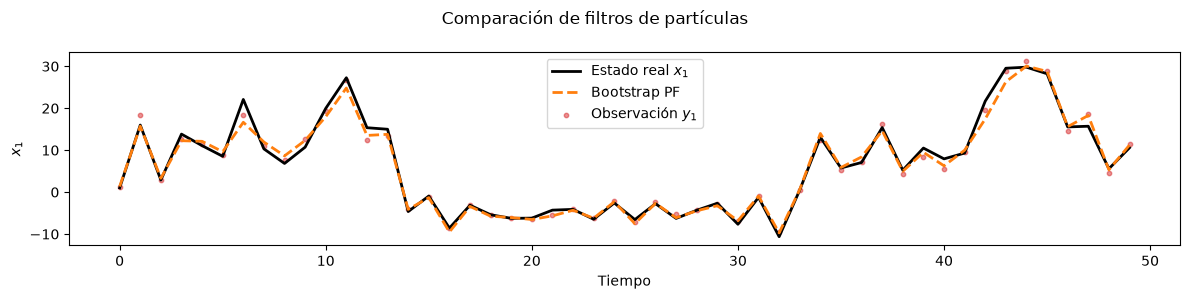

In [29]:
estimates = {"Bootstrap PF": est_bpf["estimates"]}

plot_results(x_true, y_obs, estimates)